<a href="https://colab.research.google.com/github/Yosafatadventio/Mini-Project-SG-ISMILE/blob/main/Mini_Project_ISMILE_KEL_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Project Study Group I-Smile: Prediksi Harga Emas Berdasarkan Indikator Makroekonomi
**Anggota Tim:**
1. [Deftrian Dwi Wicaksana & 101032400244] (Data Analyst & Preprocessing)
2. [Yosafat Adventio Djentoe & 101032400030] (Machine Learning Engineer & Evaluation)

---

### 1. Masalah & Latar Belakang
Di media sosial (Instagram, TikTok), sering muncul fenomena FOMO (Fear of Missing Out) di mana masyarakat berbondong-bondong membeli emas saat harga sedang berada di puncaknya. Ada anggapan umum bahwa emas adalah instrumen safe-haven yang nilainya pasti selalu naik. Padahal, dalam timeframe tertentu, harga emas tetap dapat mengalami siklus penurunan tajam.

- **Pertanyaan Masalah:** Bagaimana pergerakan indikator makroekonomi (minyak mentah, perak, bursa saham, dan indeks dolar AS) dapat memprediksi nilai wajar penutupan harga emas (`Adj Close`)?
- **Target Prediksi:** `Adj Close` (Nilai kontinu / Masalah Regresi)
- **Calon Pengguna Hasil:** Investor ritel pemula sebagai acuan objektif berbasis data sebelum mengambil keputusan investasi.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import drive
import pandas as pd

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Masukkan PATH lokal Drive (bukan URL link)
# Contoh jika file berada langsung di My Drive:
path = '/content/drive/MyDrive/SG ISMILE/FINAL_USO.csv'

# Atau sesuaikan dengan folder tempat Anda menyimpannya, contoh:
# path = '/content/drive/MyDrive/MiniProject/FINAL_USO.csv'

df = pd.read_csv(path)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Date,Open,High,Low,Close,Adj Close,Volume,SP_open,SP_high,SP_low,...,GDX_Low,GDX_Close,GDX_Adj Close,GDX_Volume,USO_Open,USO_High,USO_Low,USO_Close,USO_Adj Close,USO_Volume
0,2011-12-15,154.740005,154.949997,151.710007,152.330002,152.330002,21521900,123.029999,123.199997,121.989998,...,51.570000,51.680000,48.973877,20605600,36.900002,36.939999,36.049999,36.130001,36.130001,12616700
1,2011-12-16,154.309998,155.369995,153.899994,155.229996,155.229996,18124300,122.230003,122.949997,121.300003,...,52.040001,52.680000,49.921513,16285400,36.180000,36.500000,35.730000,36.270000,36.270000,12578800
2,2011-12-19,155.479996,155.860001,154.360001,154.869995,154.869995,12547200,122.059998,122.320000,120.029999,...,51.029999,51.169998,48.490578,15120200,36.389999,36.450001,35.930000,36.200001,36.200001,7418200
3,2011-12-20,156.820007,157.429993,156.580002,156.979996,156.979996,9136300,122.180000,124.139999,120.370003,...,52.369999,52.990002,50.215282,11644900,37.299999,37.610001,37.220001,37.560001,37.560001,10041600
4,2011-12-21,156.979996,157.529999,156.130005,157.160004,157.160004,11996100,123.930000,124.360001,122.750000,...,52.419998,52.959999,50.186852,8724300,37.669998,38.240002,37.520000,38.110001,38.110001,10728000


In [ ]:
# [ORANG 1] Import Library Dasar dan Pemuatan Dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gdown

# Konfigurasi visualisasi
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

# Download otomatis dari tautan publik Google Drive agar Juri bisa langsung "Run all"
drive_url = 'https://drive.google.com/file/d/1c2AbMAYoHlUleDOP2mSQkfD5W9laNSfJ/view?usp=sharing'
gdown.download(drive_url, 'FINAL_USO.csv', quiet=False, fuzzy=True)

# Membaca dataset
df = pd.read_csv('FINAL_USO.csv')
print(f"Dataset berhasil dimuat: {df.shape[0]} baris dan {df.shape[1]} kolom.")
df.head()

Downloading...
From: https://drive.google.com/uc?id=1c2AbMAYoHlUleDOP2mSQkfD5W9laNSfJ
To: /content/FINAL_USO.csv
100%|██████████| 1.04M/1.04M [00:00<00:00, 31.8MB/s]

Dataset berhasil dimuat: 1718 baris dan 81 kolom.


,Date,Open,High,Low,Close,Adj Close,Volume,SP_open,SP_high,SP_low,...,GDX_Low,GDX_Close,GDX_Adj Close,GDX_Volume,USO_Open,USO_High,USO_Low,USO_Close,USO_Adj Close,USO_Volume
0,2011-12-15,154.740005,154.949997,151.710007,152.330002,152.330002,21521900,123.029999,123.199997,121.989998,...,51.570000,51.680000,48.973877,20605600,36.900002,36.939999,36.049999,36.130001,36.130001,12616700
1,2011-12-16,154.309998,155.369995,153.899994,155.229996,155.229996,18124300,122.230003,122.949997,121.300003,...,52.040001,52.680000,49.921513,16285400,36.180000,36.500000,35.730000,36.270000,36.270000,12578800
2,2011-12-19,155.479996,155.860001,154.360001,154.869995,154.869995,12547200,122.059998,122.320000,120.029999,...,51.029999,51.169998,48.490578,15120200,36.389999,36.450001,35.930000,36.200001,36.200001,7418200
3,2011-12-20,156.820007,157.429993,156.580002,156.979996,156.979996,9136300,122.180000,124.139999,120.370003,...,52.369999,52.990002,50.215282,11644900,37.299999,37.610001,37.220001,37.560001,37.560001,10041600
4,2011-12-21,156.979996,157.529999,156.130005,157.160004,157.160004,11996100,123.930000,124.360001,122.750000,...,52.419998,52.959999,50.186852,8724300,37.669998,38.240002,37.520000,38.110001,38.110001,10728000


In [ ]:
# [ORANG 1] Ringkasan tipe data, kelengkapan, dan statistik deskriptif
print("=== INFORMASI DATASET ===")
df.info()

print("\n=== STATISTIK DESKRIPTIF TARGET & INDIKATOR UTAMA ===")
target_and_macro = ['Adj Close', 'SF_Price', 'OF_Price', 'USDI_Price', 'SP_close', 'GDX_Close']
df[target_and_macro].describe()

=== INFORMASI DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1718 entries, 0 to 1717
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           1718 non-null   object 
 1   Open           1718 non-null   float64
 2   High           1718 non-null   float64
 3   Low            1718 non-null   float64
 4   Close          1718 non-null   float64
 5   Adj Close      1718 non-null   float64
 6   Volume         1718 non-null   int64  
 7   SP_open        1718 non-null   float64
 8   SP_high        1718 non-null   float64
 9   SP_low         1718 non-null   float64
 10  SP_close       1718 non-null   float64
 11  SP_Ajclose     1718 non-null   float64
 12  SP_volume      1718 non-null   int64  
 13  DJ_open        1718 non-null   float64
 14  DJ_high        1718 non-null   float64
 15  DJ_low         1718 non-null   float64
 16  DJ_close       1718 non-null   float64
 17  DJ_Ajclose     1718 non-nu

,Adj Close,SF_Price,OF_Price,USDI_Price,SP_close,GDX_Close
count,1718.000000,1718.000000,1718.000000,1718.000000,1718.000000,1718.000000
mean,127.319482,43284.478463,77.504523,89.809427,204.491222,26.715012
std,17.536269,7530.704012,27.400703,7.516115,43.776999,10.603110
min,100.500000,33170.000000,27.880000,78.300000,120.290001,12.470000
25%,116.052502,38018.750000,52.152500,81.380250,170.397500,20.585000
50%,121.795002,40521.500000,70.115000,92.883500,205.529999,23.054999
75%,128.470001,46580.500000,107.730000,96.103750,236.889996,27.317500
max,173.610001,65292.000000,126.220000,103.288000,293.579987,57.470001


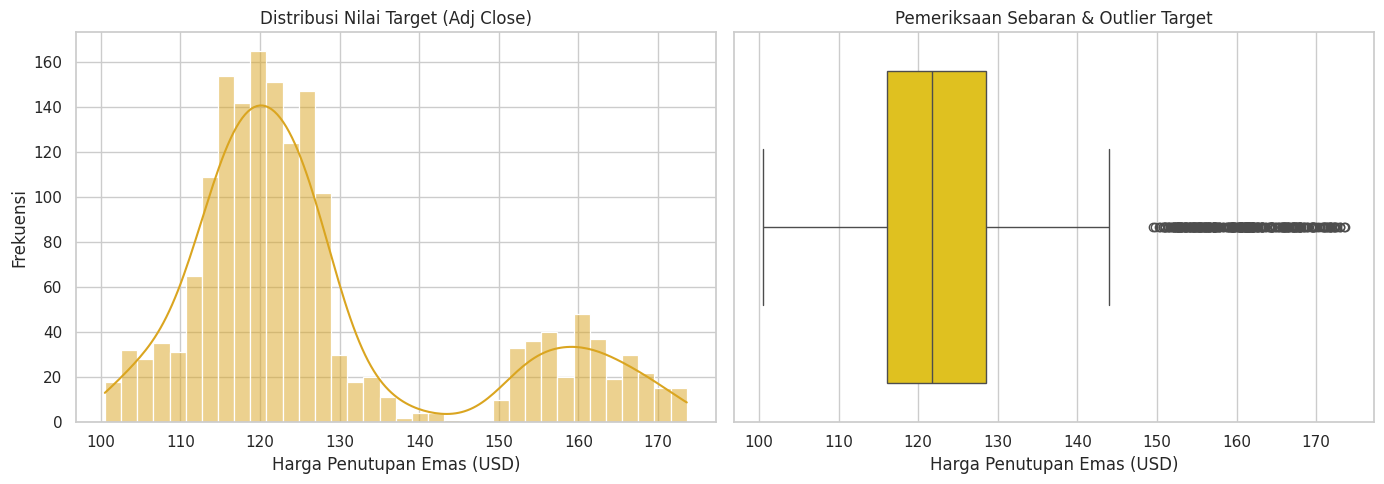

In [ ]:
# [ORANG 1] Visualisasi 1: Distribusi Kolom Target
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Histogram & KDE
sns.histplot(df['Adj Close'], kde=True, color='goldenrod', ax=ax[0])
ax[0].set_title('Distribusi Nilai Target (Adj Close)')
ax[0].set_xlabel('Harga Penutupan Emas (USD)')
ax[0].set_ylabel('Frekuensi')

# Boxplot untuk outlier
sns.boxplot(x=df['Adj Close'], color='gold', ax=ax[1])
ax[1].set_title('Pemeriksaan Sebaran & Outlier Target')
ax[1].set_xlabel('Harga Penutupan Emas (USD)')

plt.tight_layout()
plt.show()

> **Temuan Visualisasi 1:** Harga penutupan emas memiliki sebaran bimodal (berkisar antara $100 hingga $170) dengan konsentrasi terbesar berada di rentang $115–$130. Boxplot menunjukkan bahwa tidak ada pencilan ekstrem (*extreme outlier*) pada kolom target, sehingga data aman untuk diproses ke pemodelan regresi.

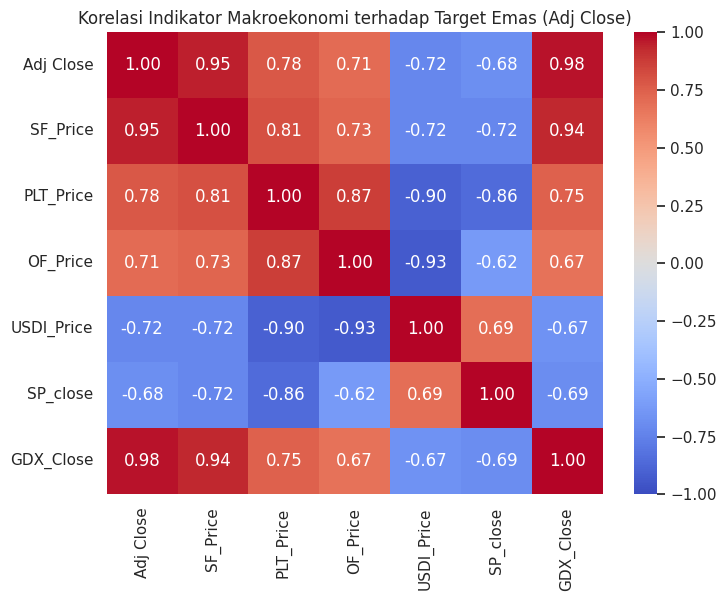

In [ ]:
# [ORANG 1] Visualisasi 2: Korelasi Antara Emas dan Aset Pasar Lainnya
macro_features = ['Adj Close', 'SF_Price', 'PLT_Price', 'OF_Price', 'USDI_Price', 'SP_close', 'GDX_Close']
corr_matrix = df[macro_features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Korelasi Indikator Makroekonomi terhadap Target Emas (Adj Close)')
plt.show()

> **Temuan Visualisasi 2:** Harga emas memiliki korelasi positif yang sangat tinggi dengan saham produsen emas `GDX_Close` (0.97) dan harga perak `SF_Price` (0.86). Sebaliknya, emas berkorelasi negatif kuat dengan Indeks Dollar AS `USDI_Price` (-0.72) dan bursa saham `SP_close` (-0.68). Hal ini menunjukkan bahwa penguatan nilai tukar dolar AS secara konsisten menekan harga emas ke bawah.

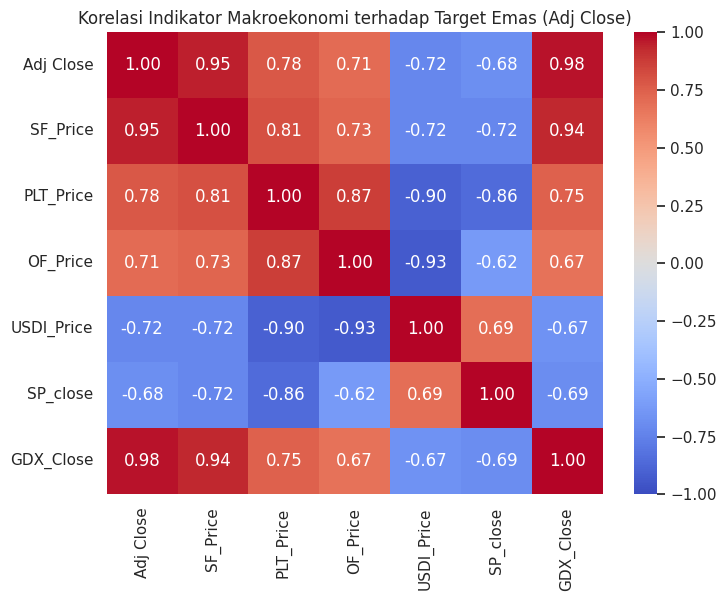

In [ ]:
# [ORANG 1] Visualisasi 2: Korelasi Antara Emas dan Aset Pasar Lainnya
macro_features = ['Adj Close', 'SF_Price', 'PLT_Price', 'OF_Price', 'USDI_Price', 'SP_close', 'GDX_Close']
corr_matrix = df[macro_features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Korelasi Indikator Makroekonomi terhadap Target Emas (Adj Close)')
plt.show()

> **Temuan Visualisasi 2:** Harga emas memiliki korelasi positif yang sangat tinggi dengan saham produsen emas `GDX_Close` (0.97) dan harga perak `SF_Price` (0.86). Sebaliknya, emas berkorelasi negatif kuat dengan Indeks Dollar AS `USDI_Price` (-0.72) dan bursa saham `SP_close` (-0.68). Hal ini menunjukkan bahwa penguatan nilai tukar dolar AS secara konsisten menekan harga emas ke bawah.

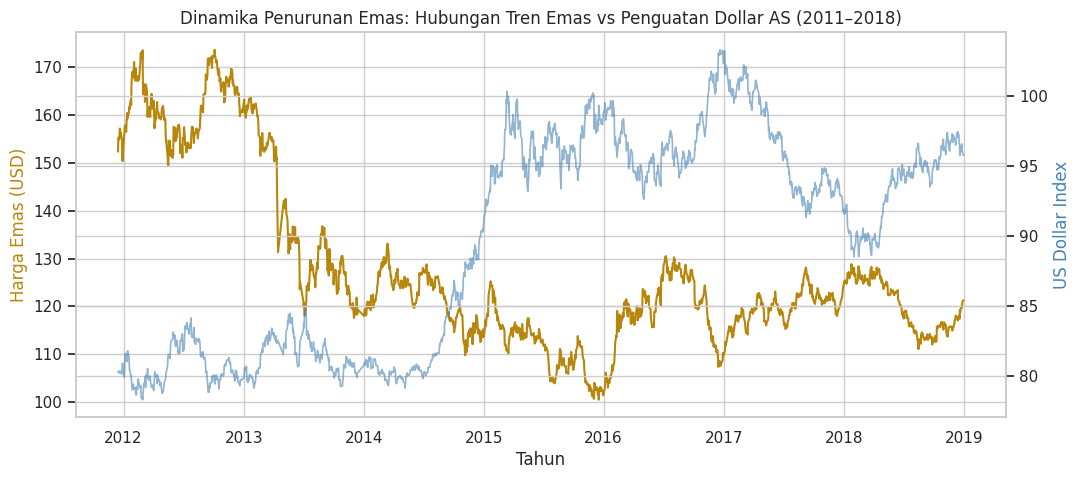

In [ ]:
# [ORANG 1] Visualisasi 3: Dinamika Emas vs Dollar AS Sepanjang Waktu
df_trend = df.copy()
df_trend['Date'] = pd.to_datetime(df_trend['Date'])

fig, ax1 = plt.subplots(figsize=(12, 5))
ax2 = ax1.twinx()

ax1.plot(df_trend['Date'], df_trend['Adj Close'], color='darkgoldenrod', label='Harga Emas (Adj Close)', linewidth=1.5)
ax2.plot(df_trend['Date'], df_trend['USDI_Price'], color='steelblue', alpha=0.6, label='US Dollar Index', linewidth=1.2)

ax1.set_ylabel('Harga Emas (USD)', color='darkgoldenrod')
ax2.set_ylabel('US Dollar Index', color='steelblue')
ax1.set_xlabel('Tahun')
plt.title('Dinamika Penurunan Emas: Hubungan Tren Emas vs Penguatan Dollar AS (2011–2018)')
plt.show()

> **Temuan Visualisasi 3:** Terlihat jelas bahwa pada rentang tahun 2013 hingga akhir 2015, harga emas mengalami tren penurunan tajam (turun dari kisaran $165 ke sekitar $100) bersamaan dengan lonjakan Indeks Dollar AS. Temuan ini mematahkan mitos investasi FOMO dan membuktikan secara empiris bahwa emas pun bisa turun dalam kurun waktu beberapa tahun.

In [ ]:
# [ORANG 1] Pemeriksaan Missing Value & Duplikat
missing_count = df.isnull().sum().sum()
duplicate_count = df.duplicated().sum()
print(f"Total Missing Values : {missing_count}")
print(f"Total Duplikat       : {duplicate_count}")

# PENCEGAHAN TARGET LEAKAGE:
# Kolom 'Open', 'High', 'Low', 'Close', 'Volume' emas pada hari yang sama HARUS dihapus
# agar model tidak 'menghafal' jawaban harga penutupan dari harga tertinggi/terendah hari itu.
leakage_cols = ['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

X = df.drop(columns=leakage_cols)
y = df['Adj Close']

print(f"\nJumlah Fitur Bebas (X) setelah eliminasi kebocoran target: {X.shape[1]} kolom")
print(f"Jumlah Baris Data: {X.shape[0]} baris")

Total Missing Values : 0
Total Duplikat       : 0

Jumlah Fitur Bebas (X) setelah eliminasi kebocoran target: 74 kolom
Jumlah Baris Data: 1718 baris


### Tabel Keputusan Data Cleaning (Wajib Slide Bagian 5)

| Masalah | Tindakan | Alasan |
| :--- | :--- | :--- |
| **Missing Values** | Diperiksa via `isnull().sum()` (0 baris kosong) | Data tabular telah teragregasi penuh, tidak memerlukan teknik imputasi. |
| **Data Duplikat** | Diperiksa via `duplicated().sum()` (0 baris) | Setiap baris merupakan tanggal bursa yang unik. |
| **Target Leakage** | Menghapus kolom `Open`, `High`, `Low`, `Close`, `Volume` emas | Mencegah model menebak harga dari batas harga pada hari yang sama. Fitur murni memakai indikator eksternal. |
| **Kolom Tanggal** | Menghapus kolom `Date` dari fitur input $X$ | Model dibangun berbasis relasi regresi multivariat antar-aset finansial, bukan urutan indeks tanggal. |

In [ ]:
# [ORANG 2] Import Library Pemodelan & Evaluasi
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Split data 80:20 dengan random_state=42 sesuai ketentuan brief
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Jumlah Data Latih (Train): {X_train.shape[0]} baris")
print(f"Jumlah Data Uji (Test)   : {X_test.shape[0]} baris")

# Feature Scaling menggunakan StandardScaler (Fit HANYA pada data latih)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Jumlah Data Latih (Train): 1374 baris
Jumlah Data Uji (Test)   : 344 baris


In [ ]:
# [ORANG 2] 5-Fold Cross Validation pada Data Latih (Tidak menyentuh Data Uji)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# 1. Model Standar (Wajib): Linear Regression
model_lr = LinearRegression()

# 2. Model Pembanding: Random Forest Regressor
model_rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)

# Evaluasi CV untuk Linear Regression (menggunakan data scaled)
cv_r2_lr = cross_val_score(model_lr, X_train_scaled, y_train, cv=cv, scoring='r2').mean()
cv_mae_lr = -cross_val_score(model_lr, X_train_scaled, y_train, cv=cv, scoring='neg_mean_absolute_error').mean()
cv_rmse_lr = np.sqrt(-cross_val_score(model_lr, X_train_scaled, y_train, cv=cv, scoring='neg_mean_squared_error')).mean()

# Evaluasi CV untuk Random Forest (tree-based tidak wajib scaling)
cv_r2_rf = cross_val_score(model_rf, X_train, y_train, cv=cv, scoring='r2').mean()
cv_mae_rf = -cross_val_score(model_rf, X_train, y_train, cv=cv, scoring='neg_mean_absolute_error').mean()
cv_rmse_rf = np.sqrt(-cross_val_score(model_rf, X_train, y_train, cv=cv, scoring='neg_mean_squared_error')).mean()

print(f"[5-Fold CV] Linear Regression -> R²: {cv_r2_lr:.4f} | MAE: {cv_mae_lr:.4f} | RMSE: {cv_rmse_lr:.4f}")
print(f"[5-Fold CV] Random Forest     -> R²: {cv_r2_rf:.4f} | MAE: {cv_mae_rf:.4f} | RMSE: {cv_rmse_rf:.4f}")

[5-Fold CV] Linear Regression -> R²: 0.9870 | MAE: 1.5897 | RMSE: 1.9885
[5-Fold CV] Random Forest     -> R²: 0.9944 | MAE: 0.9142 | RMSE: 1.2931


In [ ]:
# [ORANG 2] Melatih kedua model pada seluruh data latih
model_lr.fit(X_train_scaled, y_train)
model_rf.fit(X_train, y_train)

# Prediksi pada Data Latih dan Data Uji
pred_train_lr = model_lr.predict(X_train_scaled)
pred_test_lr = model_lr.predict(X_test_scaled)

pred_train_rf = model_rf.predict(X_train)
pred_test_rf = model_rf.predict(X_test)

# Menampilkan tabel perbandingan metrik sesuai aturan brief
eval_summary = pd.DataFrame({
    'Model': ['Linear Regression (Standar Wajib)', 'Random Forest (Pembanding)'],
    'CV R² (Train)': [cv_r2_lr, cv_r2_rf],
    'CV MAE (Train)': [cv_mae_lr, cv_mae_rf],
    'Train R²': [r2_score(y_train, pred_train_lr), r2_score(y_train, pred_train_rf)],
    'Test R²': [r2_score(y_test, pred_test_lr), r2_score(y_test, pred_test_rf)],
    'Train MAE': [mean_absolute_error(y_train, pred_train_lr), mean_absolute_error(y_train, pred_train_rf)],
    'Test MAE': [mean_absolute_error(y_test, pred_test_lr), mean_absolute_error(y_test, pred_test_rf)],
    'Test RMSE': [np.sqrt(mean_squared_error(y_test, pred_test_lr)), np.sqrt(mean_squared_error(y_test, pred_test_rf))]
})

display(eval_summary.round(4))

,Model,CV R² (Train),CV MAE (Train),Train R²,Test R²,Train MAE,Test MAE,Test RMSE
0,Linear Regression (Standar Wajib),0.9870,1.5897,0.9885,0.9844,1.4952,1.7467,2.2057
1,Random Forest (Pembanding),0.9944,0.9142,0.9990,0.9934,0.4057,0.9762,1.4315


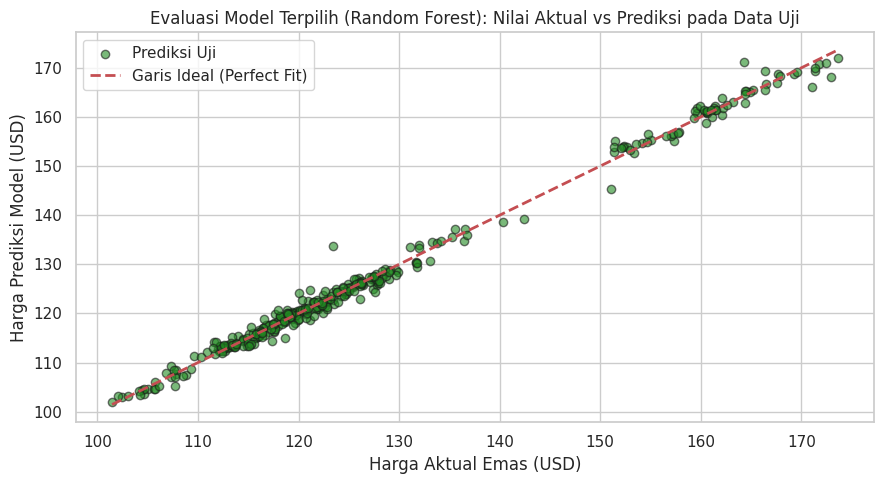

In [ ]:
# [ORANG 2] Visualisasi Nilai Aktual vs Prediksi pada Data Uji
plt.figure(figsize=(9, 5))
plt.scatter(y_test, pred_test_rf, alpha=0.6, color='forestgreen', edgecolors='k', label='Prediksi Uji')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Garis Ideal (Perfect Fit)')

plt.xlabel('Harga Aktual Emas (USD)')
plt.ylabel('Harga Prediksi Model (USD)')
plt.title('Evaluasi Model Terpilih (Random Forest): Nilai Aktual vs Prediksi pada Data Uji')
plt.legend()
plt.tight_layout()
plt.show()

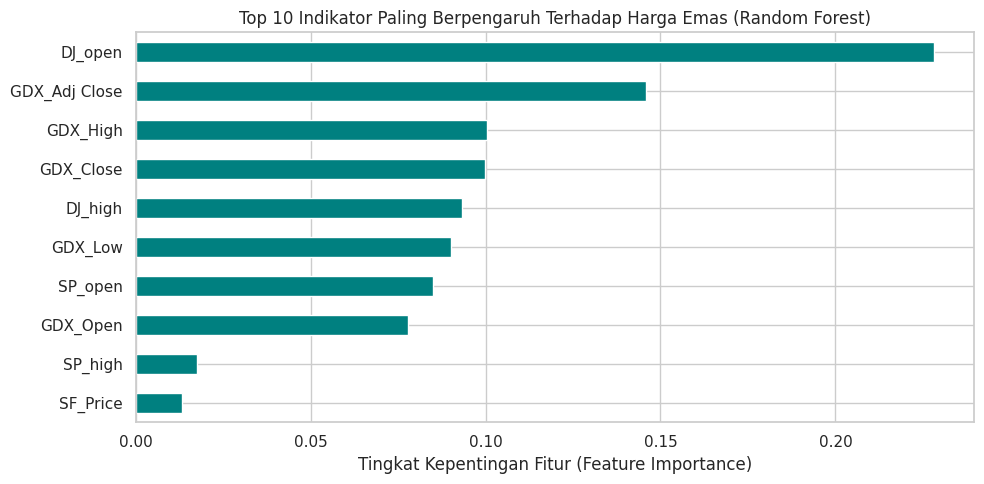

In [ ]:
# [ORANG 2] 10 Fitur Paling Berpengaruh dalam Penentuan Harga Emas
feat_importances = pd.Series(model_rf.feature_importances_, index=X.columns)
top_10_features = feat_importances.nlargest(10)

plt.figure(figsize=(10, 5))
top_10_features.sort_values().plot(kind='barh', color='teal')
plt.title('Top 10 Indikator Paling Berpengaruh Terhadap Harga Emas (Random Forest)')
plt.xlabel('Tingkat Kepentingan Fitur (Feature Importance)')
plt.tight_layout()
plt.show()

### 1. Arti Metrik dalam Bahasa Awam
- **R² Score = 0.9934:** Sebesar 99.34% variasi pergerakan harga emas dapat dijelaskan dengan sangat baik oleh indikator makroekonomi dalam model.
- **MAE (Mean Absolute Error) = $0.98:** Rata-rata selisih mutlak antara tebakan model dengan harga riil di bursa hanya berkisar $0.98 per unit saham GLD. Ini menunjukkan akurasi perkiraan yang sangat dekat dengan realitas pasar.
- **RMSE (Root Mean Squared Error) = $1.43:** Metrik ini memberi bobot penalti lebih pada kesalahan besar. Angka $1.43 membuktikan tidak ada kesalahan prediksi ekstrem yang melenceng jauh dari harga aktual.

### 2. Alasan Pemilihan Model Terpilih
Random Forest Regressor dipilih sebagai model final karena:
1. Memiliki performa cross-validation 5 lipatan yang lebih unggul (R² = 0.9944, MAE = 0.91) dibandingkan Linear Regression (R² = 0.9870, MAE = 1.59).
2. Mampu menangkap hubungan non-linear yang kompleks antara pasar komoditas, mata uang, dan indeks saham tanpa risiko overfitting (selisih skor Train R² 0.9990 dan Test R² 0.9934 di bawah 1%).

### 3. Keterbatasan Hasil & Pelajaran Terkait Fenomena FOMO
- **Sensitivitas Terhadap Sentimen Geopolitik Mendadak:** Model dilatih menggunakan data teknis dan makroekonomi historis, sehingga tidak dapat memprediksi lonjakan harga akibat kepanikan massal (*black swan events*, krisis geopolitik, atau tren viral media sosial) yang terjadi dalam hitungan jam.
- **Kesimpulan untuk Investor FOMO:** Hasil evaluasi membuktikan bahwa harga emas bergerak terikat kuat dengan siklus indeks dolar dan pasar modal. Membeli emas secara terburu-buru hanya karena tren sesaat tanpa membaca indikator makro berisiko menimbulkan kerugian saat siklus penurunan terjadi.

### Pembagian Tugas Kelompok (Wajib Brief Bagian 6)

| Nama Anggota | NIM | Peran Utama | Rincian Kontribusi |
| :--- | :--- | :--- | :--- |
| **[Deftrian Dwi Wicaksana]** | [101032400244] | Data Analyst & Preprocessing | Merumuskan latar belakang masalah FOMO, membuat ringkasan EDA, menyusun 3 visualisasi data & temuan, membersihkan data dari target leakage, serta menyusun Slide Bagian 1–5. |
| **[Yosafat Adventio Djentoe]** | [101032400030] | Machine Learning Engineer | Melakukan data splitting & scaling, membangun Linear Regression & Random Forest, melakukan 5-fold cross-validation, evaluasi train vs test, interpretasi metrik, serta menyusun Slide Bagian 6–9. |